--- OPTIMIZED TRUCK ROUTE FOUND ---
Best Route Sequence: [0, 4, 2, 5, 1, 6, 3, 0]
Total Driving Time: 98 minutes


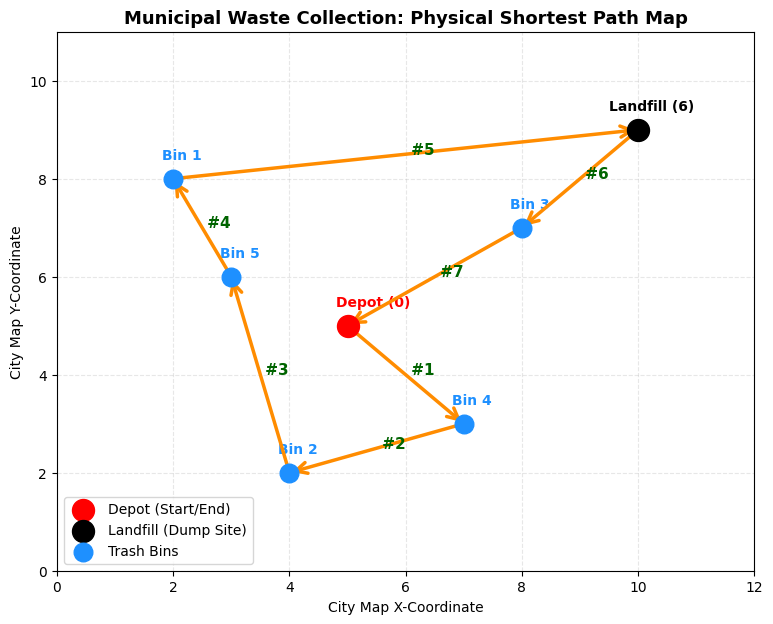

In [12]:
import random
import matplotlib.pyplot as plt

# --- 1. THE SETUP (5 Bins, 1 Depot, 1 Landfill = 7 total locations) ---
num_locations = 7
depot = 0
landfill = 6
bins = list(range(1, 6))  # Bins 1 to 5

# Set a random seed so coordinates and distances match perfectly every time
random.seed(15)

# Generate mock XY coordinates on a city grid for visual mapping
x_coords = [5, 2, 4, 8, 7, 3, 10]
y_coords = [5, 8, 2, 7, 3, 6,  9]

# Calculate real geometric distances based on those coordinates to keep it accurate
distance = [[0 for _ in range(num_locations)] for _ in range(num_locations)]
for i in range(num_locations):
    for j in range(num_locations):
        if i != j:
            dist = int(((x_coords[i] - x_coords[j])**2 + (y_coords[i] - y_coords[j])**2)**0.5 * 3) + 3
            distance[i][j] = dist
            distance[j][i] = dist

# Small trash weights (1 to 3 tons)
bin_weights = {b: random.randint(1, 3) for b in bins}
max_truck_capacity = 6  # Force a landfill trip half-way

# ACO Parameters
pheromones = [[1.0 for _ in range(num_locations)] for _ in range(num_locations)]
evaporation_rate = 0.15
num_ants = 15
num_rounds = 40

best_overall_route = []
best_overall_time = float('inf')

# --- 2. THE SIMULATION LOOP ---
for round_num in range(num_rounds):
    round_routes = []
    round_times = []

    for ant in range(num_ants):
        current_loc = depot
        visited_bins = []
        current_weight = 0
        total_time = 0
        route_taken = [depot]

        while len(visited_bins) < len(bins):
            unvisited = [b for b in bins if b not in visited_bins]
            choices = []
            scores = []

            for next_bin in unvisited:
                attraction = pheromones[current_loc][next_bin] * (1.0 / distance[current_loc][next_bin])
                choices.append(next_bin)
                scores.append(attraction)

            chosen_bin = random.choices(choices, weights=scores, k=1)[0]
            added_weight = bin_weights[chosen_bin]

            if current_weight + added_weight > max_truck_capacity:
                total_time += distance[current_loc][landfill] + distance[landfill][chosen_bin]
                route_taken.extend([landfill, chosen_bin])
                current_weight = added_weight
            else:
                total_time += distance[current_loc][chosen_bin]
                route_taken.append(chosen_bin)
                current_weight += added_weight

            visited_bins.append(chosen_bin)
            current_loc = chosen_bin

        total_time += distance[current_loc][depot]
        route_taken.append(depot)

        round_routes.append(route_taken)
        round_times.append(total_time)

    # --- EVAPORATION ---
    for i in range(num_locations):
        for j in range(num_locations):
            pheromones[i][j] *= (1.0 - evaporation_rate)

    # --- REWARD THE WINNERS ---
    for t_idx, total_time in enumerate(round_times):
        pheromone_deposit = 200.0 / total_time
        route = round_routes[t_idx]

        for step in range(len(route) - 1):
            pheromones[route[step]][route[step+1]] += pheromone_deposit

        if total_time < best_overall_time:
            best_overall_time = total_time
            best_overall_route = route

# --- 3. THE FINAL RESULT PRINTING ---
print("--- OPTIMIZED TRUCK ROUTE FOUND ---")
print(f"Best Route Sequence: {best_overall_route}")
print(f"Total Driving Time: {best_overall_time} minutes")

# --- 4. GENERATING ONLY THE PHYSICAL ROUTE MAP ---
plt.figure(figsize=(9, 7))

# Plot the locations as colorful markers (nodes)
plt.scatter(x_coords[depot], y_coords[depot], color='red', s=250, zorder=5, label='Depot (Start/End)')
plt.scatter(x_coords[landfill], y_coords[landfill], color='black', s=250, zorder=5, label='Landfill (Dump Site)')
plt.scatter([x_coords[b] for b in bins], [y_coords[b] for b in bins], color='dodgerblue', s=180, zorder=5, label='Trash Bins')

# Label each location point clearly on the grid
plt.text(x_coords[depot]-0.2, y_coords[depot]+0.4, 'Depot (0)', fontsize=10, fontweight='bold', color='red')
plt.text(x_coords[landfill]-0.5, y_coords[landfill]+0.4, 'Landfill (6)', fontsize=10, fontweight='bold', color='black')
for b in bins:
    plt.text(x_coords[b]-0.2, y_coords[b]+0.4, f'Bin {b}', fontsize=10, fontweight='bold', color='dodgerblue')

# Draw arrows following the shortest path sequence step-by-step
for idx in range(len(best_overall_route) - 1):
    start_node = best_overall_route[idx]
    end_node = best_overall_route[idx+1]

    x_start, y_start = x_coords[start_node], y_coords[start_node]
    x_end, y_end = x_coords[end_node], y_coords[end_node]

    # Draw arrow lines to show truck direction movement
    plt.annotate('', xy=(x_end, y_end), xytext=(x_start, y_start),
                 arrowprops=dict(arrowstyle="->", color='darkorange', lw=2.5, mutation_scale=20, ls='-'))

    # Label the sequence number on the path lines
    plt.text((x_start + x_end)/2, (y_start + y_end)/2, f' #{idx+1}', color='darkgreen', fontweight='bold', fontsize=11)

plt.title('Municipal Waste Collection: Physical Shortest Path Map', fontsize=13, fontweight='bold')
plt.xlim(0, 12)
plt.ylim(0, 11)
plt.xlabel('City Map X-Coordinate')
plt.ylabel('City Map Y-Coordinate')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='lower left')
plt.show()
